<a href="https://colab.research.google.com/github/rohith154-vsr/ML-2-LAB/blob/main/BAGGING_65_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Stopping criteria met at sample D53 (rolling average change: 0.00000%)
Total samples generated: 53
Average percentage of unique elements: 65.00%


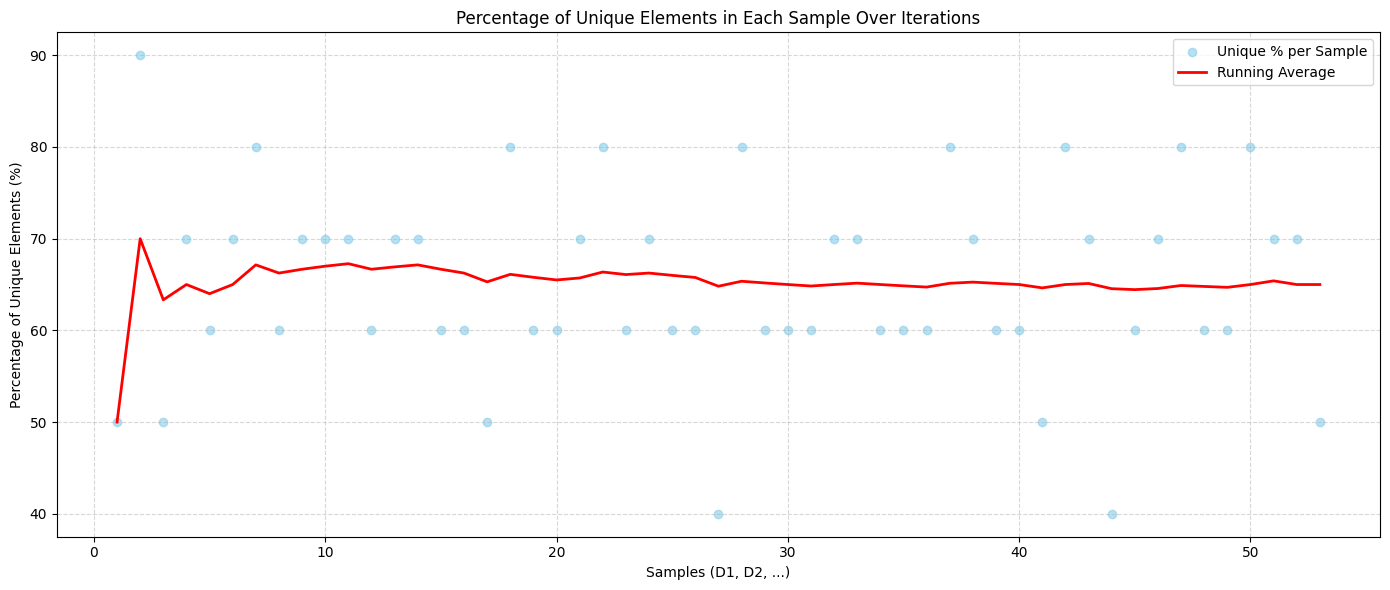

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def generate_samples_until_convergence(n_elements=10, val_range=(1, 10), window_size=50, threshold=0.001, max_samples=1000):
    samples = {}
    unique_percentages = []
    running_averages = []

    i = 1
    converged = False

    while not converged and i <= max_samples:
        sample = np.random.choice(range(val_range[0], val_range[1] + 1), size=n_elements, replace=True)
        sample_name = f"D{i}"
        samples[sample_name] = sample

        unique_count = len(np.unique(sample))
        unique_pct = (unique_count / n_elements) * 100
        unique_percentages.append(unique_pct)

        if i >= window_size:
            current_avg = np.mean(unique_percentages[-window_size:])
            running_averages.append(current_avg)

            if len(running_averages) > 2:
                change = abs(running_averages[-1] - running_averages[-2])
                if change < threshold:
                    converged = True
                    print(f"Stopping criteria met at sample {sample_name} (rolling average change: {change:.5f}%)")
        else:
            running_averages.append(np.mean(unique_percentages))

        i += 1

    return samples, unique_percentages, running_averages

samples, unique_pcts, running_avgs = generate_samples_until_convergence()

print(f"Total samples generated: {len(samples)}")
print(f"Average percentage of unique elements: {running_avgs[-1]:.2f}%")

plt.figure(figsize=(14, 6))
sample_indices = list(range(1, len(unique_pcts) + 1))

plt.scatter(sample_indices, unique_pcts, color='skyblue', alpha=0.6, label='Unique % per Sample')
plt.plot(sample_indices, running_avgs, color='red', linewidth=2, label='Running Average')

plt.title('Percentage of Unique Elements in Each Sample Over Iterations')
plt.xlabel('Samples (D1, D2, ...)')
plt.ylabel('Percentage of Unique Elements (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()